# MatBench Bandgap Preciction

<div style="background-color: #f8d7da; border-left: 6px solid #ccc; margin: 20px; padding: 15px;">
    <strong>💡 Margaret Atwood:</strong> Every aspect of human technology has a dark side, including the bow and arrow.
</div>

## 🏅 Initial prompt from MaterialsML Coursework

It is time to go back to supervised machine learning problems.

You have been assigned one dataset from [MatBench](https://matbench.materialsproject.org) as introduced in the [Lecture slides](https://speakerdeck.com/aronwalsh/mlformaterials-challenge-25). You are free to choose and tune any machine-learning model, with any Python library, but it should be appropriate for the problem. For instance, [XGBoost](https://xgboost.readthedocs.io) could be a good starting starting point to build a regression model. You can refer back to earlier notebooks and repurpose code as needed. 

You may reach the limits of computing processing power on Google Colab. Building a useful model with limited resources is a real-world skill. Using other free resources is allowed if you find an alternative service, as is running on your own computer. A model tracker such as [wandb](https://wandb.ai) could be helpful for advanced users. If you want to try a brute force approach, a library such as [Automatminer](https://hackingmaterials.lbl.gov/automatminer) may be of interest.

This notebook should be used for keeping a record of your model development, submission, and even your presentation. You are free to edit (add/remove/delete) or rearrange the cells as you see fit.


## Data preparation

Check the data distribution and apply appropriate pre-processing steps as required. 

In [4]:
# Get dataset info from matminer
from matminer.datasets import get_all_dataset_info
from matminer.datasets import load_dataset

# Detailed on https://hackingmaterials.lbl.gov/matminer/dataset_summary.html
# Uncomment the info line for your assigned challenge code 

  # A 
#info = get_all_dataset_info("matbench_dielectric")

  # B 
info = get_all_dataset_info("matbench_expt_gap")

  # C 
#info = get_all_dataset_info("matbench_expt_is_metal")

  # D 
#info = get_all_dataset_info("matbench_glass")

  # E 
#info = get_all_dataset_info("matbench_steels")

# Check the dataset information
print(info)

Dataset: matbench_expt_gap
Description: Matbench v0.1 test dataset for predicting experimental band gap from composition alone. Retrieved from Zhuo et al. supplementary information. Deduplicated according to composition, removing compositions with reported band gaps spanning more than a 0.1eV range; remaining compositions were assigned values based on the closest experimental value to the mean experimental value for that composition among all reports. For benchmarking w/ nested cross validation, the order of the dataset must be identical to the retrieved data; refer to the Automatminer/Matbench publication for more details.
Columns:
	composition: Chemical formula.
	gap expt: Target variable. Experimentally measured gap, in eV.
Num Entries: 4604
Reference: Y. Zhuo, A. Masouri Tehrani, J. Brgoch (2018) Predicting the Band Gaps of Inorganic Solids by Machine Learning J. Phys. Chem. Lett. 2018, 9, 7, 1668-1673 https:doi.org/10.1021/acs.jpclett.8b00124.
Bibtex citations: ["@Article{Dunn2020

In [12]:
from elementembeddings.composition import composition_featuriser

# Load dataset into a pandas DataFrame
df = load_dataset("matbench_expt_gap")

#print(df)
#df.head(10)

# Featurize composition with Magpie
magpie_df = composition_featuriser(df, formula_column="composition", embedding='magpie', stats=["mean", "variance"])
magpie_df.head()

Featurising compositions...


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4604/4604 [00:01<00:00, 2528.10it/s]


Computing feature vectors...


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4604/4604 [00:00<00:00, 249053.03it/s]


,composition,gap expt,mean_Number,mean_MendeleevNumber,mean_AtomicWeight,mean_MeltingT,mean_Column,mean_Row,mean_CovalentRadius,mean_Electronegativity,...,variance_NValence,variance_NsUnfilled,variance_NpUnfilled,variance_NdUnfilled,variance_NfUnfilled,variance_NUnfilled,variance_GSvolume_pa,variance_GSbandgap,variance_GSmagmom,variance_SpaceGroupNumber
0,Ag(AuS)2,0.00,47.400000,74.600000,113.186268,937.262000,13.000000,4.600000,125.400000,2.434000,...,75.440000,0.240000,0.960000,0.000000,0.0,0.240000,20.376958,1.163713,0.0,5766.000000
1,Ag(W3Br7)2,0.00,46.714286,81.000000,110.931629,1291.720476,13.571429,4.619048,133.190476,2.739524,...,3.959184,0.045351,0.222222,7.346939,0.0,5.102041,39.845889,0.471744,0.0,6008.820862
2,Ag0.5Ge1Pb1.75S4,1.83,36.275862,83.482759,85.163324,611.499655,14.896552,4.000000,119.724138,2.396207,...,81.700357,0.064209,1.407848,0.000000,0.0,1.110583,8.312116,1.088311,0.0,5941.973841
3,Ag0.5Ge1Pb1.75Se4,1.51,46.206897,84.034483,111.036428,669.783793,14.896552,4.551724,128.000000,2.379655,...,31.854935,0.064209,1.407848,0.000000,0.0,1.110583,8.386297,0.128759,0.0,11011.139120
4,Ag2BBr,0.00,33.500000,74.250000,76.612850,1270.915000,13.000000,4.000000,123.500000,2.215000,...,24.750000,0.250000,4.250000,0.000000,0.0,3.000000,63.199323,0.555959,0.0,4325.500000


In [6]:
from matminer.featurizers.structure.composite import JarvisCFID

# Add structure features
#structure_featuriser = JarvisCFID()
#structure_featuriser.set_n_jobs(1)
#magpie_df = structure_featuriser.fit_featurize_dataframe(magpie_df, col_id='composition')
#magpie_df.head()

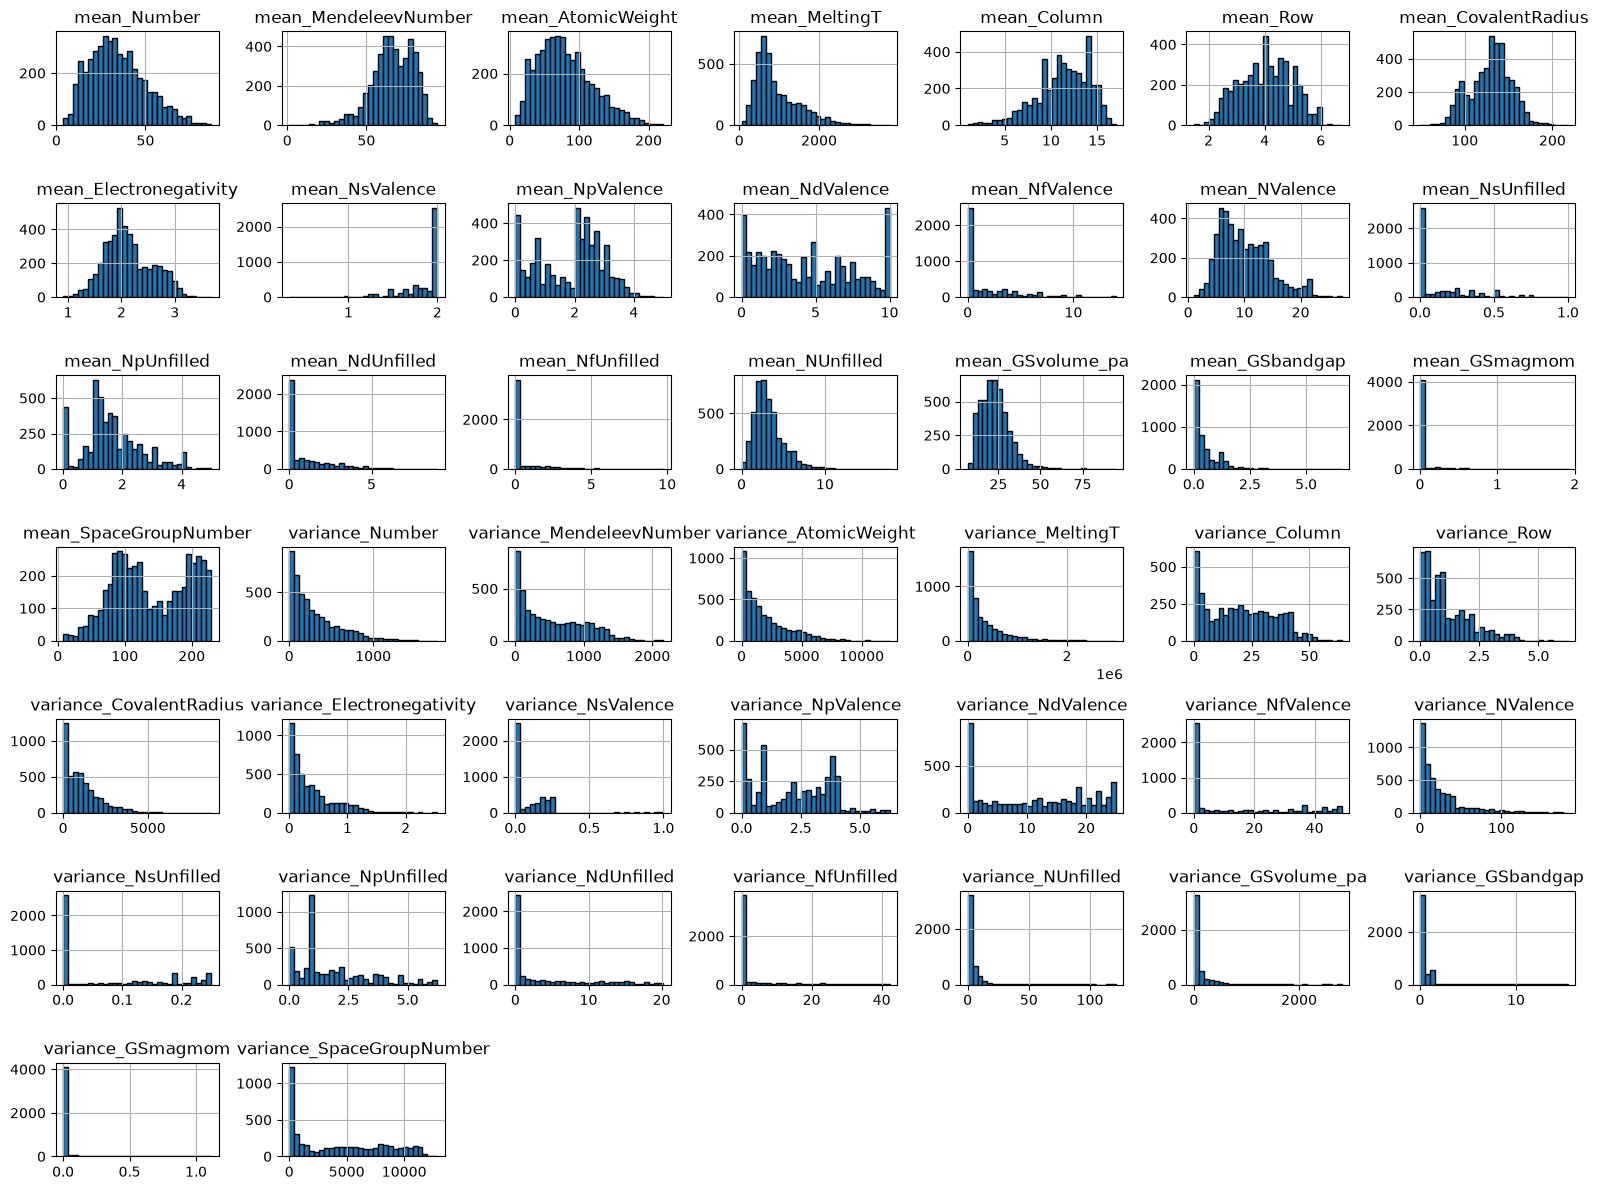

In [7]:
# Separate out datasets

import matplotlib.pyplot as plt

feature_df = magpie_df.drop(columns=["composition", "gap expt"])


feature_df.hist(
    bins=30,
    figsize=(16, 12),
    layout=None,
    edgecolor="black"
)

plt.tight_layout()
plt.show()

AttributeError: Rectangle.set() got an unexpected keyword argument 'layout'

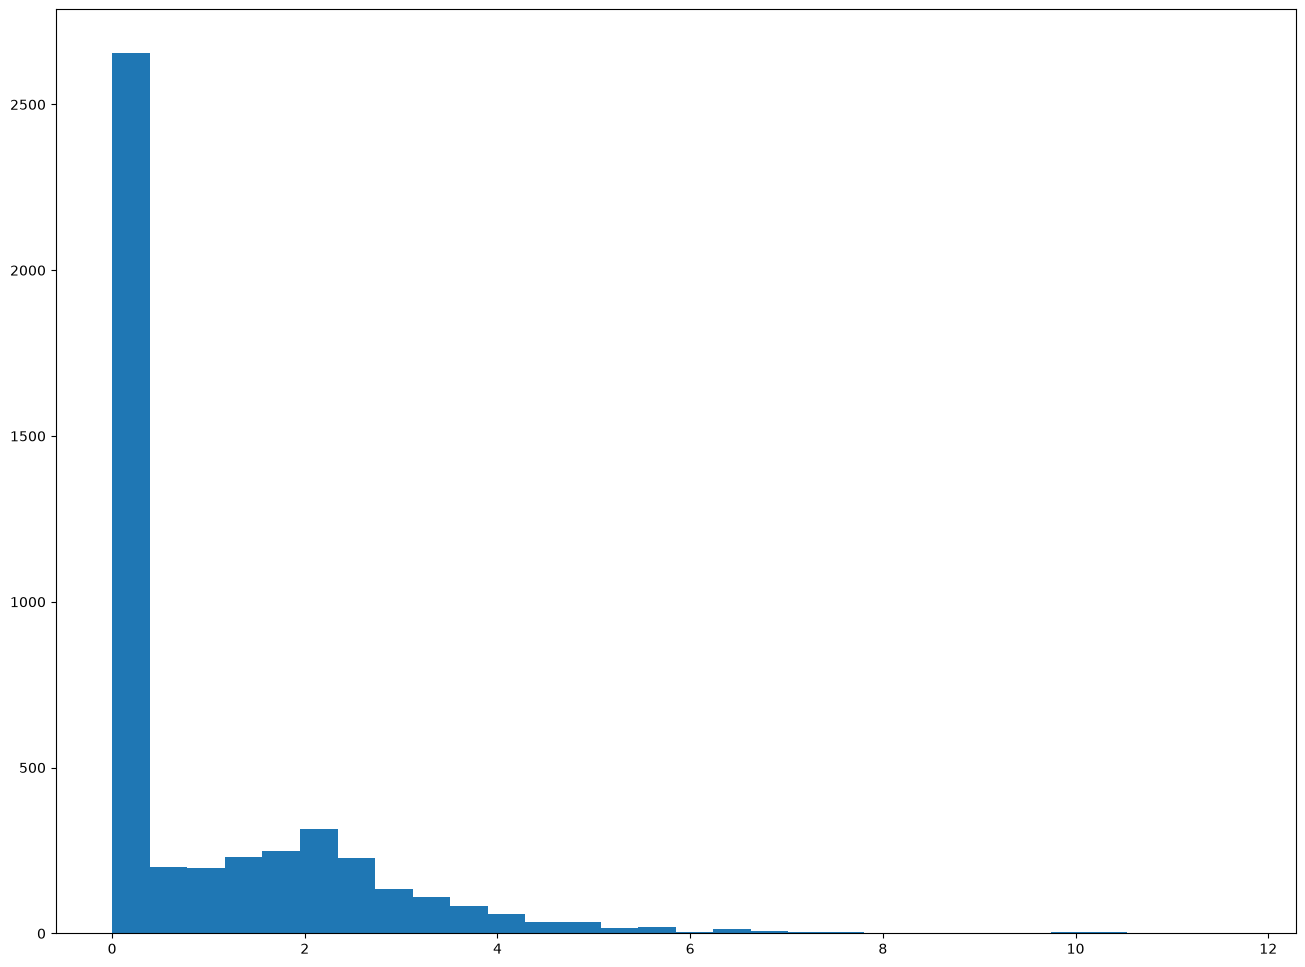

In [8]:
y = magpie_df['gap expt']


y.hist(
    bins=30,
    figsize=(16, 12),
    layout=None,
    edgecolor="black"
)

plt.tight_layout()
plt.show()

In [9]:
# No scaling needed
X = feature_df.copy()
y = magpie_df['gap expt']

from sklearn.model_selection import train_test_split

# Split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Print the sizes of the arrays
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (3683, 44)
y_train shape: (3683,)
X_test shape: (921, 44)
y_test shape: (921,)


Relevant features chosen [matminer](https://hackingmaterials.lbl.gov/matminer/).

## Model selection, testing and training 


In [10]:
# Wrap the lines of code for later sections
def make_prediction_plot(X, y, model, label):
    y_pred = model.predict(X)  # Calculate predictions here
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.scatter(y, y_pred, c=y, cmap='viridis')
    ax.plot(y, y, 'r-')
    ax.set_xlabel(f'{label} True')
    ax.set_ylabel(f'{label} Predicted')
    plt.show()
    return y_pred  # Return y_pred

XGBoost Cross-Validation Results
  Mean RMSE: 0.891
  Standard Deviation of RMSE: 0.018


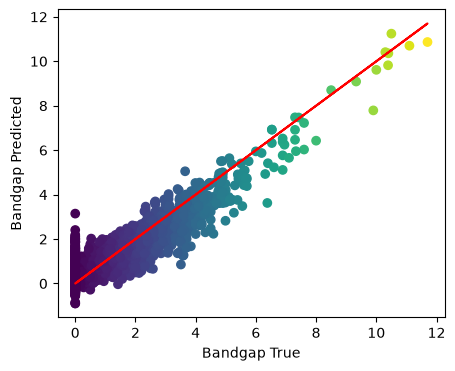


Random Forest Cross-Validation Results
  Mean RMSE: 1.125
  Standard Deviation of RMSE: 0.045


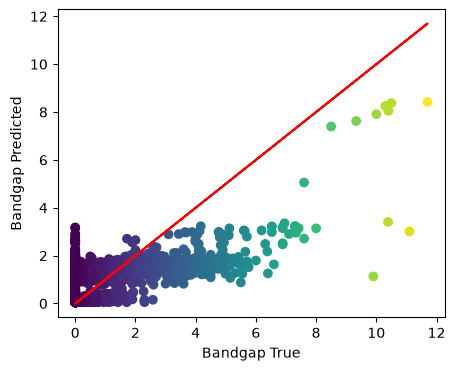

array([1.2687405 , 0.05407824, 1.5778847 , ..., 0.05407824, 0.12920943,
       0.88119841], shape=(3683,))

In [11]:
from sklearn.model_selection import cross_val_score
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn import metrics
import numpy as np

# Define models
xgb_model = XGBRegressor(n_estimators=100, max_depth=3, random_state=42, objective='reg:squarederror')
rf_model = RandomForestRegressor(n_estimators=100, max_depth=3, random_state=42)

# Perform cross-validation for XGBoost
xgb_cv_scores = cross_val_score(xgb_model, X_train, y_train, cv=5, scoring='neg_mean_squared_error')
xgb_rmse = np.sqrt(-xgb_cv_scores)  # Convert to RMSE

# Perform cross-validation for Random Forest
rf_cv_scores = cross_val_score(rf_model, X_train, y_train, cv=5, scoring='neg_mean_squared_error')
rf_rmse = np.sqrt(-rf_cv_scores)  # Convert to RMSE

xgb_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

# Print results
# Compare the results
print("XGBoost Cross-Validation Results")
print(f"  Mean RMSE: {xgb_rmse.mean():.3f}")
print(f"  Standard Deviation of RMSE: {xgb_rmse.std():.3f}")
make_prediction_plot(X_train, y_train, xgb_model, 'Bandgap')

print("\nRandom Forest Cross-Validation Results")
print(f"  Mean RMSE: {rf_rmse.mean():.3f}")
print(f"  Standard Deviation of RMSE: {rf_rmse.std():.3f}")
make_prediction_plot(X_train, y_train, rf_model, 'Bandgap')



Train, validate and test your model. Make sure to do proper data splits and to consider the hyperparamaters of your model.

In [59]:
from skopt import gp_minimize
from skopt.space import Integer, Real
from skopt.utils import use_named_args

from xgboost import XGBRegressor
from sklearn.model_selection import cross_val_score
import numpy as np

space = [
    Integer(2, 10, name='max_depth'),
    Real(0.01, 0.3, prior='log-uniform', name='learning_rate'),
    Integer(100, 800, name='n_estimators'),
    Real(0.6, 1.0, name='subsample'),
    Real(0.6, 1.0, name='colsample_bytree'),
    Integer(1, 10, name='min_child_weight')
]



In [60]:
@use_named_args(space)
def objective(**params):

    model = XGBRegressor(
        **params,
        objective='reg:squarederror',
        random_state=42,
        n_jobs=1
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring='neg_root_mean_squared_error',
        n_jobs=-1
    )

    return -scores.mean()

In [61]:
result = gp_minimize(
    func=objective,
    dimensions=space,
    n_calls=50,
    n_initial_points=10,
    random_state=42,
    verbose=True
)

Iteration No: 1 started. Evaluating function at random point.
Iteration No: 1 ended. Evaluation done at random point.
Time taken: 5.0838
Function value obtained: 0.8031
Current minimum: 0.8031
Iteration No: 2 started. Evaluating function at random point.
Iteration No: 2 ended. Evaluation done at random point.
Time taken: 0.9651
Function value obtained: 0.8368
Current minimum: 0.8031
Iteration No: 3 started. Evaluating function at random point.
Iteration No: 3 ended. Evaluation done at random point.
Time taken: 8.4376
Function value obtained: 0.8074
Current minimum: 0.8031
Iteration No: 4 started. Evaluating function at random point.
Iteration No: 4 ended. Evaluation done at random point.
Time taken: 0.7611
Function value obtained: 0.9286
Current minimum: 0.8031
Iteration No: 5 started. Evaluating function at random point.
Iteration No: 5 ended. Evaluation done at random point.
Time taken: 0.3395
Function value obtained: 0.8638
Current minimum: 0.8031
Iteration No: 6 started. Evaluating

In [62]:
best_params = {
    dim.name: value
    for dim, value in zip(space, result.x)
}

print("Best hyperparameters:")
for name, value in best_params.items():
    print(f"{name}: {value}")

print(f"\nBest CV RMSE: {result.fun:.4f} eV")

Best hyperparameters:
max_depth: 10
learning_rate: 0.01761257436582909
n_estimators: 800
subsample: 0.7306612330276064
colsample_bytree: 0.6
min_child_weight: 1

Best CV RMSE: 0.7943 eV


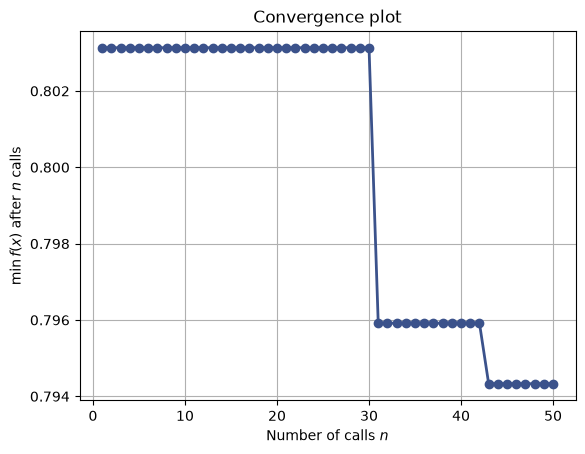

In [63]:
from skopt.plots import plot_convergence
import matplotlib.pyplot as plt

plot_convergence(result)
plt.show()

## Model analysis and discussion


XGBoost Cross-Validation Results
  Mean RMSE: 0.794
  Standard Deviation of RMSE: 0.026


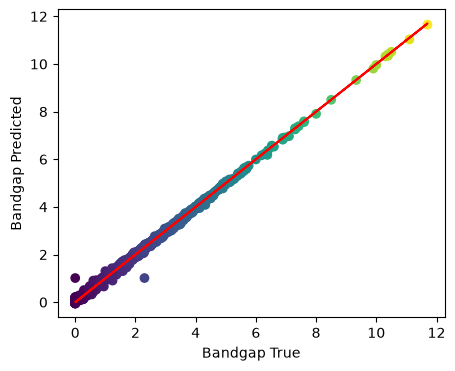

The training MAE = 0.029 eV
The training RMSE = 0.053 eV
The training r^2 = 0.999


In [64]:
best_xgb_model = XGBRegressor(
    **best_params,
    objective='reg:squarederror',
    random_state=42
)

xgb_cv_scores = cross_val_score(best_xgb_model, X_train, y_train, cv=5, scoring='neg_mean_squared_error')
xgb_rmse = np.sqrt(-xgb_cv_scores)  # Convert to RMSE
best_xgb_model.fit(X_train, y_train)

print("XGBoost Cross-Validation Results")
print(f"  Mean RMSE: {xgb_rmse.mean():.3f}")
print(f"  Standard Deviation of RMSE: {xgb_rmse.std():.3f}")

y_pred_train = make_prediction_plot(X_train, y_train, best_xgb_model, 'Bandgap')
print(f'The training MAE = {metrics.mean_absolute_error(y_train, y_pred_train):.3f} eV')
print(f'The training RMSE = {np.sqrt(metrics.mean_squared_error(y_train, y_pred_train)):.3f} eV')
print(f'The training r^2 = {best_xgb_model.score(X_train, y_train):.3f}')


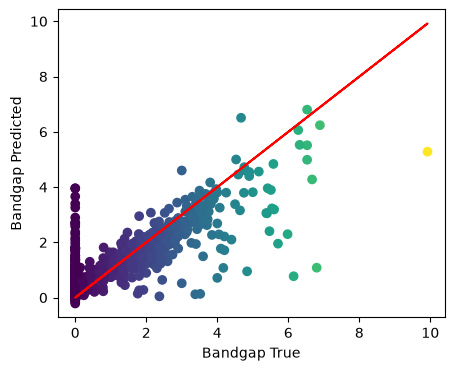

The MAE = 0.418 eV
The RMSE = 0.806 eV
The R² = 0.698


In [65]:
# Evaluate on previously unseen test data
# Performance
best_xgb_model.fit(X_train, y_train)

y_pred = make_prediction_plot(X_test, y_test, best_xgb_model, 'Bandgap')


print(f'The MAE = {metrics.mean_absolute_error(y_test, y_pred):.3f} eV')
print(f'The RMSE = {np.sqrt(metrics.mean_squared_error(y_test, y_pred)):.3f} eV')
print(f'The R² = {best_xgb_model.score(X_test, y_test):.3f}')


With magpie mean and varience get Mean RMSE: 0.794 + Standard Deviation of RMSE: 0.026 \
0.418 eV MAE, relative to 0.3327 eV on Matbench.